# 02 - The zoom audit: do metric depth models respect a digital zoom?

Results come from `scripts/run_audit.py` on Kaggle GPUs:
- main set: 8 runs (7 models + Metric3D with stale K), 200 images per set, 800 per model;
- model ladder: larger variants and newer families (DA3, UniK3D, VGGT), 100 images per set.

Per image we fit two exponents (see `src/analysis.py`):
- **alpha**: depth of the same pixels scales like s^-alpha. Ideal 0. A model that only
  reads apparent size gives 1 (twice as big = twice as close).
- **beta**: predicted focal scales like s^beta. Ideal 1.

Control: the *blur* row degrades the image like a 2x zoom without changing the field
of view. If depth moved as much under blur, interpolation would be the explanation.

In [1]:
import json
import sys
from pathlib import Path

import matplotlib.pyplot as plt
import numpy as np

ROOT = Path.cwd().parent if Path.cwd().name == "notebooks" else Path.cwd()
sys.path.insert(0, str(ROOT / "src"))

import analysis as A
import plotstyle as ps

ps.use()
TAB = ROOT / "outputs/tables"
TAB.mkdir(parents=True, exist_ok=True)
MAIN = ["dav2-s", "dav2-b", "zoedepth", "depthpro", "moge2-s", "unidepth2-s", "metric3d-s", "metric3d-s-staleK"]
LADDER = ["dav2-l", "moge2-b", "moge2-l", "unidepth2-b", "unidepth2-l", "unik3d-l",
          "da3-nested", "da3-metric-l", "metric3d-l", "da3-l", "vggt"]
RELATIVE = {"da3-l", "vggt"}  # depth normalised per scene: only beta is meaningful

df = A.load()
present = set(df.model)
MAIN = [m for m in MAIN if m in present]
LADDER = [m for m in LADDER if m in present]
print(df.groupby(["model", "dataset"]).name.nunique().unstack())

dataset            diode-in  diode-out  kitti  nyu
model                                             
dav2-b                  200        200    200  200
dav2-s                  200        200    200  200
dav2-s-anchor           200        200    200  200
dav2-s-eft              200        200    200  200
dav2-s-eftb             200        200    200  200
dav2-s-fixed            200        200    200  200
depthpro                200        200    200  200
metric3d-s              200        200    200  200
metric3d-s-staleK       200        200    200  200
moge2-s                 200        200    200  200
unidepth2-s             200        200    200  200
zoedepth                200        200    200  200


In [2]:
pi = A.per_image(df[df.model.isin(MAIN + LADDER)])
pi.loc[pi.model.isin(RELATIVE), "alpha"] = np.nan
summ = A.summary(pi).merge(A.blur_control(df).reset_index(), on=["model", "dataset"], how="left")
summ.to_csv(TAB / "audit_by_model_dataset.csv", index=False)

## Table 1: pooled over the four sets

In [3]:
pooled = A.summary(pi, by=("model",)).set_index("model")
pooled["blur2"] = A.blur_control(df).groupby("model").mean()
pooled["alpha_plus_beta"] = pi.assign(ab=pi.alpha + pi.beta).groupby("model").ab.median()
cols = ["n", "alpha", "alpha_lo", "alpha_hi", "beta", "alpha_plus_beta", "die2", "blur2", "absrel1", "absrel3"]
t1 = pooled.loc[[m for m in MAIN + LADDER if m in pooled.index], cols]
t1.index = [ps.LABEL.get(m, m) for m in t1.index]
t1.round(3).to_csv(TAB / "table1_pooled.csv")
t1.round(3)

,n,alpha,alpha_lo,alpha_hi,beta,alpha_plus_beta,die2,blur2,absrel1,absrel3
DA-V2-S,800,0.954,0.925,0.990,NaN,NaN,0.608,0.013,0.317,0.652
DA-V2-B,800,0.852,0.820,0.874,NaN,NaN,0.579,0.008,0.313,0.599
ZoeDepth,800,0.614,0.582,0.639,NaN,NaN,0.438,0.007,0.310,0.539
Depth Pro,800,0.311,0.271,0.336,0.651,0.974,0.253,0.028,0.310,0.459
MoGe-2-S,800,0.363,0.337,0.382,0.558,0.945,0.244,0.031,0.274,0.465
UniDepthV2-S,800,0.343,0.299,0.395,0.447,0.874,0.264,0.040,0.824,0.792
Metric3D v2-S,800,-0.073,-0.083,-0.063,NaN,NaN,0.074,0.016,0.142,0.358
Metric3D v2-S (stale K),800,0.927,0.917,0.937,NaN,NaN,0.641,0.016,0.142,0.628


## Figure 2: how depth and focal move with zoom (main models)

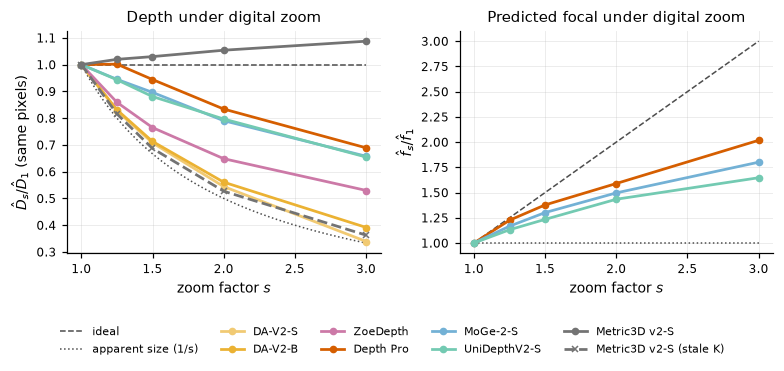

In [4]:
z = df[df.kind == "zoom"].copy()
z["log_fx"] = np.log(z.fx / z.fx_base)
curve = z.groupby(["model", "zoom"]).agg(depth=("log_ratio_self", "median"), focal=("log_fx", "median"),
                                         s=("s_true", "median")).reset_index()

fig, (a1, a2) = plt.subplots(1, 2, figsize=(7.2, 3.3))
ss = np.linspace(1, 3, 50)
a1.plot(ss, np.ones_like(ss), color="0.3", lw=1, ls="--", label="ideal")
a1.plot(ss, 1 / ss, color="0.3", lw=1, ls=":", label="apparent size (1/s)")
a2.plot(ss, ss, color="0.3", lw=1, ls="--", label="ideal (f·s)")
a2.plot(ss, np.ones_like(ss), color="0.3", lw=1, ls=":", label="ignores zoom")
for m in MAIN:
    c = curve[curve.model == m].sort_values("zoom")
    a1.plot(c.s, np.exp(c.depth), **ps.line(m))
    if c.focal.notna().all():
        a2.plot(c.s, np.exp(c.focal), **ps.line(m))
a1.set(xlabel="zoom factor $s$", ylabel=r"$\hat D_s / \hat D_1$ (same pixels)", title="Depth under digital zoom")
a2.set(xlabel="zoom factor $s$", ylabel=r"$\hat f_s / \hat f_1$", title="Predicted focal under digital zoom")
h1, l1 = a1.get_legend_handles_labels()
fig.legend(h1, l1, ncol=5, loc="lower center", bbox_to_anchor=(0.5, -0.02))
fig.tight_layout(rect=(0, 0.13, 1, 1))
ps.save(fig, "fig2_depth_and_focal_vs_zoom")

## Figure 3: the alpha-beta plane
Each point is one model (median over images, all four sets). The ideal model sits at
(beta, alpha) = (1, 0); a model that reasons from apparent size lies on alpha + beta = 1
(lateral sizes preserved), and a model that ignores the camera at (0, 1).

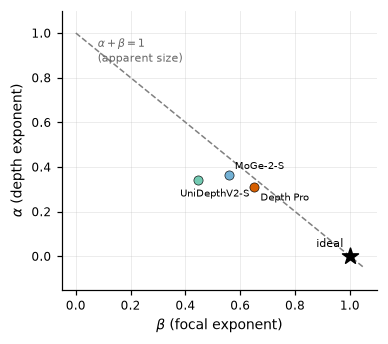

In [5]:
LABEL_OFFSET = {"unidepth2-s": (-12, -11), "moge2-s": (4, 4), "depthpro": (4, -9)}  # avoid overlaps
fig, ax = plt.subplots(figsize=(3.6, 3.2))
b = np.linspace(0, 1.05, 10)
ax.plot(b, 1 - b, color="0.5", lw=1, ls="--")
ax.text(0.08, 0.98, r"$\alpha+\beta=1$" + "\n(apparent size)", fontsize=7, color="0.4", va="top")
ax.scatter([1], [0], marker="*", s=120, color="k", zorder=5)
ax.annotate("ideal", (1, 0), textcoords="offset points", xytext=(-22, 6), fontsize=7)
for m in [m for m in MAIN + LADDER if m in pooled.index]:
    r = pooled.loc[m]
    if np.isfinite(r.beta) and np.isfinite(r.alpha):
        ax.scatter(r.beta, r.alpha, color=ps.colour(m), s=36, edgecolor="k", lw=0.4, zorder=4)
        ax.annotate(ps.LABEL.get(m, m), (r.beta, r.alpha), textcoords="offset points",
                    xytext=LABEL_OFFSET.get(m, (4, 3)), fontsize=6.5)
ax.set(xlabel=r"$\beta$ (focal exponent)", ylabel=r"$\alpha$ (depth exponent)", xlim=(-0.05, 1.1), ylim=(-0.15, 1.1))
fig.tight_layout()
ps.save(fig, "fig3_alpha_beta_plane")

## Figure 4: does a bigger model fix it? (model ladder)

In [6]:
params_f = A.RESULTS / "params.json"
if params_f.exists() and LADDER:
    params = json.loads(params_f.read_text())
    fig, axes = plt.subplots(1, 2, figsize=(7.2, 2.8))
    for ax, metric, ylab in ((axes[0], "alpha", r"$\alpha$ (0 = ideal)"), (axes[1], "beta", r"$\beta$ (1 = ideal)")):
        for fam in ("dav2", "moge2", "unidepth2", "unik3d", "metric3d", "da3", "depthpro", "vggt"):
            ms = [m for m in pooled.index if ps.family(m) == fam and m in params and not m.endswith("staleK")]
            ms = [m for m in ms if np.isfinite(pooled.loc[m, metric])]
            if not ms:
                continue
            ms.sort(key=lambda m: params[m])
            x = [params[m] / 1e6 for m in ms]
            y = [pooled.loc[m, metric] for m in ms]
            ax.plot(x, y, "-", color=ps.colour(ms[-1]), lw=1.2)
            for m, xi, yi in zip(ms, x, y):
                ax.scatter(xi, yi, color=ps.colour(m), s=30, edgecolor="k", lw=0.4, zorder=4)
                ax.annotate(ps.LABEL.get(m, m), (xi, yi), textcoords="offset points", xytext=(3, 3), fontsize=6)
        ax.set(xscale="log", xlabel="parameters (M)", ylabel=ylab)
    axes[0].axhline(0, color="k", lw=0.8)
    axes[1].axhline(1, color="k", lw=0.8)
    fig.tight_layout()
    ps.save(fig, "fig4_model_ladder")

## Per-dataset alpha (with 95% bootstrap CI)

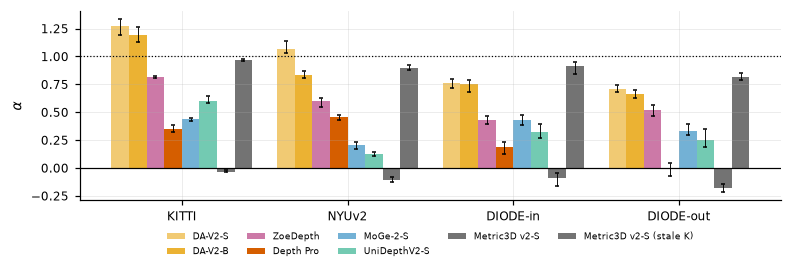

In [7]:
show = [m for m in MAIN + LADDER if m not in RELATIVE]
fig, ax = plt.subplots(figsize=(7.2, 2.6))
width = 0.85 / len(show)
for k, m in enumerate(show):
    s = summ[summ.model == m].set_index("dataset").reindex(A.DATASETS)
    x = np.arange(len(A.DATASETS)) + k * width
    ax.bar(x, s.alpha, width, yerr=[s.alpha - s.alpha_lo, s.alpha_hi - s.alpha], color=ps.colour(m),
           label=ps.LABEL.get(m, m), capsize=1.5, error_kw=dict(lw=0.6))
ax.axhline(0, color="k", lw=0.8)
ax.axhline(1, color="k", ls=":", lw=0.8)
ax.set_xticks(np.arange(len(A.DATASETS)) + 0.425 - width / 2, [A.PRETTY_DS[d] for d in A.DATASETS])
ax.set_ylabel(r"$\alpha$")
ax.legend(fontsize=6, ncol=5, loc="upper center", bbox_to_anchor=(0.5, -0.12))
fig.tight_layout()
ps.save(fig, "figS_alpha_per_dataset")